JS05 Praktikum 2 - Pengaruh hyperparameter HDBSCAN + evaluasi clustering.

Catatan API: sklearn.cluster.HDBSCAN tidak punya dbscan_clustering(cut_distance).
Padanan yang dipakai: potong single linkage tree HDBSCAN pada jarak tertentu
(scipy fcluster, criterion='distance') -> ekuivalen flat cut yang dilakukan
dbscan_clustering(). Konsekuensi: tidak ada label noise (-1) pada hasil cut.

In [1]:
# Shim: notebook tidak punya __file__, kode ini warisan script .py.
import os
__file__ = os.path.abspath("hyperparameter_hdbscan.ipynb")
print("base:", os.path.dirname(__file__))

base: C:\code\pemmes26\js05-klasterisasi-hierarki\praktikum-2


In [2]:
from pathlib import Path

import matplotlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.cluster.hierarchy import fcluster
from sklearn.cluster import HDBSCAN
from sklearn.datasets import make_blobs
from sklearn.metrics import (adjusted_rand_score, davies_bouldin_score,
                             silhouette_score)

OUT = Path(__file__).resolve().parent / "output"
OUT.mkdir(parents=True, exist_ok=True)
ROWS = []

In [3]:
def plot(X, labels, probabilities=None, parameters=None, ground_truth=False, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(10, 4))
    labels = np.asarray(labels) if labels is not None else np.ones(len(X), dtype=int)
    probabilities = probabilities if probabilities is not None else np.ones(len(X))
    unique_labels = set(labels)
    colors = [plt.cm.Spectral(each) for each in np.linspace(0, 1, len(unique_labels))]
    for k, col in zip(unique_labels, colors):
        if k == -1:
            col = [0, 0, 0, 1]
        for ci in (labels == k).nonzero()[0]:
            ax.plot(X[ci, 0], X[ci, 1], "x" if k == -1 else "o",
                    markerfacecolor=tuple(col), markeredgecolor="k",
                    markersize=4 if k == -1 else 1 + 5 * probabilities[ci])
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    title = f"{'True' if ground_truth else 'Estimated'} number of clusters: {n_clusters}"
    if parameters is not None:
        title += " | " + ", ".join(f"{k}={v}" for k, v in parameters.items())
    ax.set_title(title)
    ax.set_xticks([])
    ax.set_yticks([])

In [4]:
def cut_tree(hdb, distance, min_samples=5):
    """Flat cut single-linkage tree pada jarak -> label, cluster kecil jadi noise.

    hdbscan.dbscan_clustering() memotong tree lalu menandai titik di cluster
    berukuran < min_samples sebagai noise; perilaku itu direplikasi di sini.
    """
    z = np.column_stack([hdb._single_linkage_tree_["left_node"],
                         hdb._single_linkage_tree_["right_node"],
                         hdb._single_linkage_tree_["value"],
                         hdb._single_linkage_tree_["cluster_size"]]).astype(float)
    lab = fcluster(z, t=distance, criterion="distance")
    sizes = np.bincount(lab)
    small = np.where(sizes < min_samples)[0]
    lab = np.where(np.isin(lab, small[small > 0]), -1, lab)
    uniq = {c: i for i, c in enumerate(sorted(set(lab) - {-1}))}
    return np.array([uniq.get(c, -1) for c in lab])

In [5]:
def evaluate(X, labels, labels_true, tag):
    labels = np.asarray(labels)
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    n_noise = int((labels == -1).sum())
    sil = dbi = np.nan
    if 1 < n_clusters < len(labels):
        sil = silhouette_score(X, labels)
        dbi = davies_bouldin_score(X, labels)
    ari = adjusted_rand_score(labels_true, labels)
    print(f"  {tag:<34} cluster={n_clusters} noise={n_noise:>3} "
          f"silhouette={sil:.4f} DBI={dbi:.4f} ARI={ari:.4f}")
    ROWS.append(dict(eksperimen=tag, n_cluster=n_clusters, n_noise=n_noise,
                     silhouette=sil, davies_bouldin=dbi, ari=ari))
    return sil, dbi

In [6]:
def save(fig, name):
    fig.tight_layout()
    fig.savefig(OUT / name, dpi=110)
    print(f"  -> output/{name}")

In [7]:
# Dataset lanjutan praktikum 1 (Langkah 6): 4 cluster, kepadatan berbeda
centers = [[-0.85, -0.85], [-0.85, 0.85], [3, 3], [3, -3]]
X, labels_true = make_blobs(n_samples=750, centers=centers,
                            cluster_std=[0.2, 0.35, 1.35, 1.35], random_state=0)

[Langkah 7] min_cluster_size


  min_cluster_size=5                 cluster=4 noise= 32 silhouette=0.5716 DBI=1.5931 ARI=0.9212


  min_cluster_size=3                 cluster=90 noise=254 silhouette=0.0077 DBI=1.4236 ARI=0.0295


  min_cluster_size=25                cluster=4 noise= 90 silhouette=0.5108 DBI=1.6190 ARI=0.8234


  -> output/p2_min_cluster_size.png


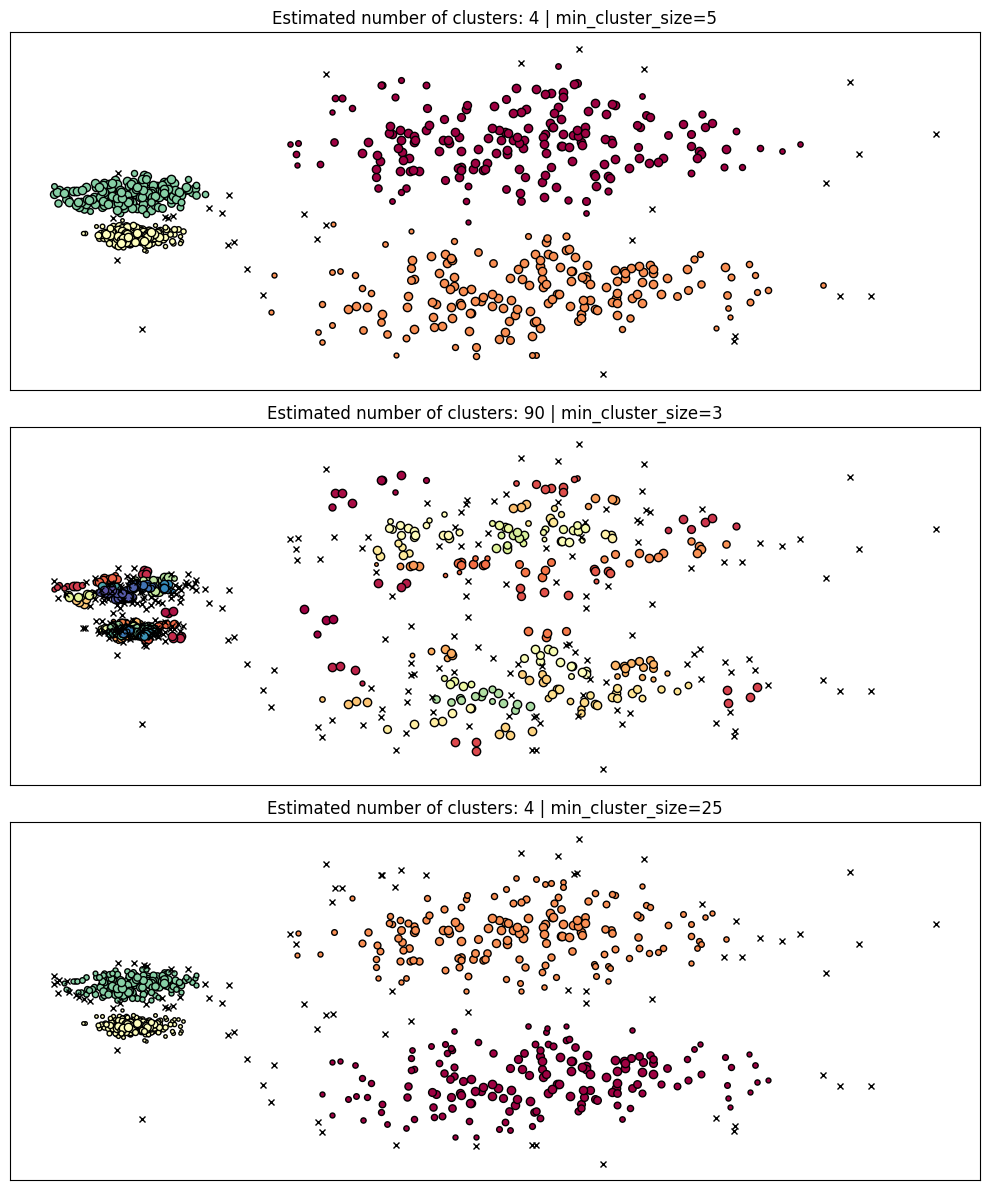

In [8]:
# ---------------------------------------------------------------- Langkah 7
print("[Langkah 7] min_cluster_size")
PARAM = ({"min_cluster_size": 5}, {"min_cluster_size": 3}, {"min_cluster_size": 25})
fig, axes = plt.subplots(3, 1, figsize=(10, 12))
for i, param in enumerate(PARAM):
    hdb = HDBSCAN(**param).fit(X)
    plot(X, hdb.labels_, hdb.probabilities_, param, ax=axes[i])
    evaluate(X, hdb.labels_, labels_true, f"min_cluster_size={param['min_cluster_size']}")
save(fig, "p2_min_cluster_size.png")

[Langkah 8] min_samples (min_cluster_size=20)


  min_samples=5                      cluster=4 noise= 32 silhouette=0.5716 DBI=1.5931 ARI=0.9212


  min_samples=3                      cluster=4 noise= 19 silhouette=0.5789 DBI=1.5220 ARI=0.9515


  min_samples=25                     cluster=4 noise= 90 silhouette=0.5108 DBI=1.6190 ARI=0.8234


  -> output/p2_min_samples.png


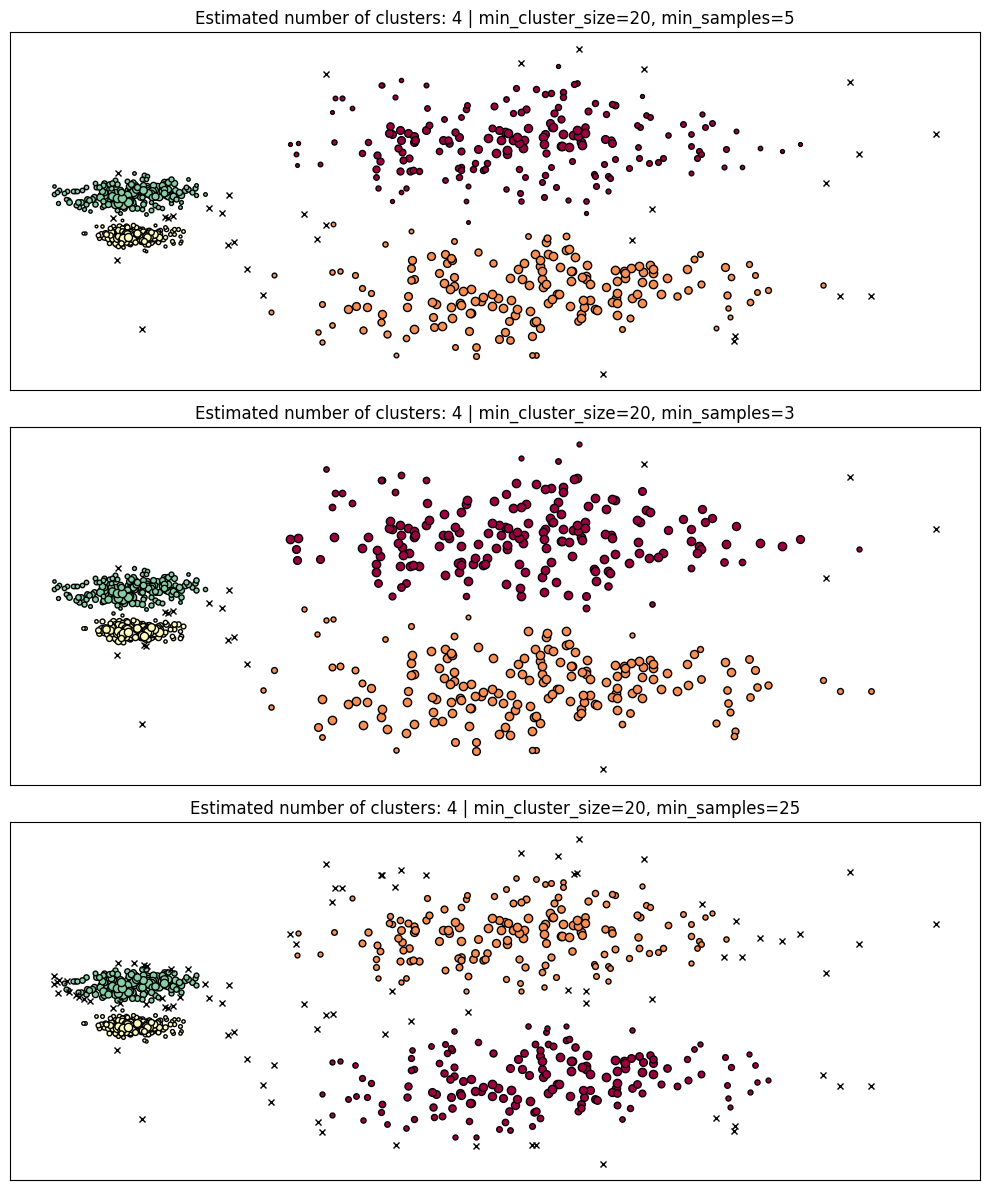

In [9]:
# ---------------------------------------------------------------- Langkah 8
print("[Langkah 8] min_samples (min_cluster_size=20)")
PARAM = ({"min_cluster_size": 20, "min_samples": 5},
         {"min_cluster_size": 20, "min_samples": 3},
         {"min_cluster_size": 20, "min_samples": 25})
fig, axes = plt.subplots(3, 1, figsize=(10, 12))
for i, param in enumerate(PARAM):
    hdb = HDBSCAN(**param).fit(X)
    plot(X, hdb.labels_, hdb.probabilities_, param, ax=axes[i])
    evaluate(X, hdb.labels_, labels_true, f"min_samples={param['min_samples']}")
save(fig, "p2_min_samples.png")

[Langkah 9] cut_distance pada single linkage tree HDBSCAN


  cut_distance=0.1                   cluster=3 noise=529 silhouette=0.0068 DBI=1.2311 ARI=0.2444


  cut_distance=0.5                   cluster=3 noise= 99 silhouette=0.5498 DBI=1.5204 ARI=0.5541


  cut_distance=1.0                   cluster=1 noise= 15 silhouette=nan DBI=nan ARI=0.0005


  -> output/p2_cut_distance.png


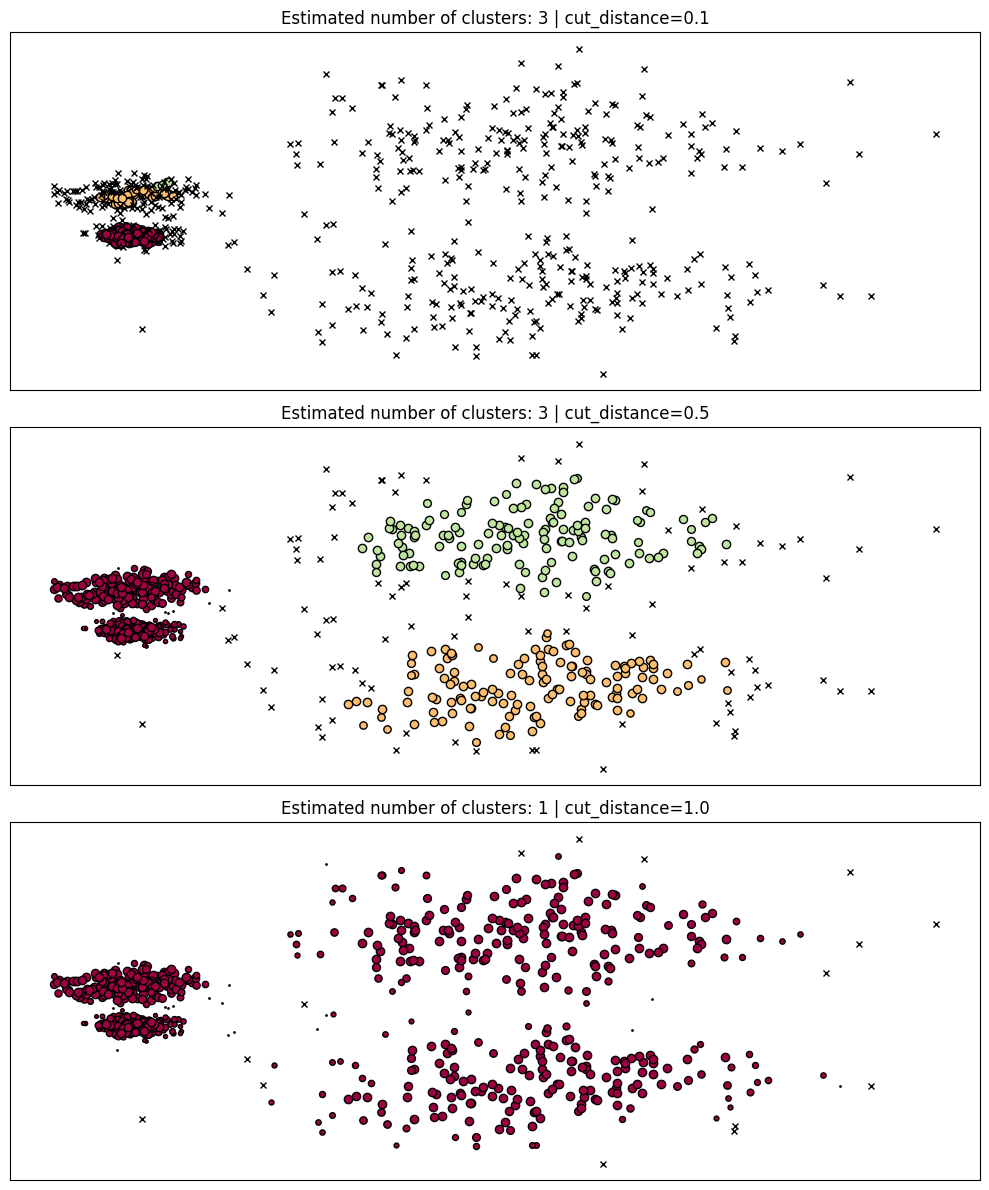

In [10]:
# ---------------------------------------------------------------- Langkah 9
print("[Langkah 9] cut_distance pada single linkage tree HDBSCAN")
PARAM = ({"cut_distance": 0.1}, {"cut_distance": 0.5}, {"cut_distance": 1.0})
hdb = HDBSCAN().fit(X)
fig, axes = plt.subplots(len(PARAM), 1, figsize=(10, 12))
for i, param in enumerate(PARAM):
    labels = cut_tree(hdb, param["cut_distance"])
    plot(X, labels, hdb.probabilities_, param, ax=axes[i])
    evaluate(X, labels, labels_true, f"cut_distance={param['cut_distance']}")
save(fig, "p2_cut_distance.png")

[Langkah 10-11] Evaluasi clustering HDBSCAN default
  Silhouette Score      : 0.5716
  Davies-Bouldin Index  : 1.5931
  -> output/p2_evaluasi_bar.png

[ringkasan] 9 eksperimen, metrik -> output/p2_metrik.csv
         eksperimen  n_cluster  n_noise  silhouette  davies_bouldin      ari
 min_cluster_size=5          4       32    0.571571        1.593075 0.921234
 min_cluster_size=3         90      254    0.007655        1.423626 0.029476
min_cluster_size=25          4       90    0.510781        1.618963 0.823434
      min_samples=5          4       32    0.571571        1.593075 0.921234
      min_samples=3          4       19    0.578917        1.522037 0.951463
     min_samples=25          4       90    0.510781        1.618963 0.823434
   cut_distance=0.1          3      529    0.006777        1.231121 0.244430
   cut_distance=0.5          3       99    0.549811        1.520383 0.554069
   cut_distance=1.0          1       15         NaN             NaN 0.000518

Catatan: silhouette &

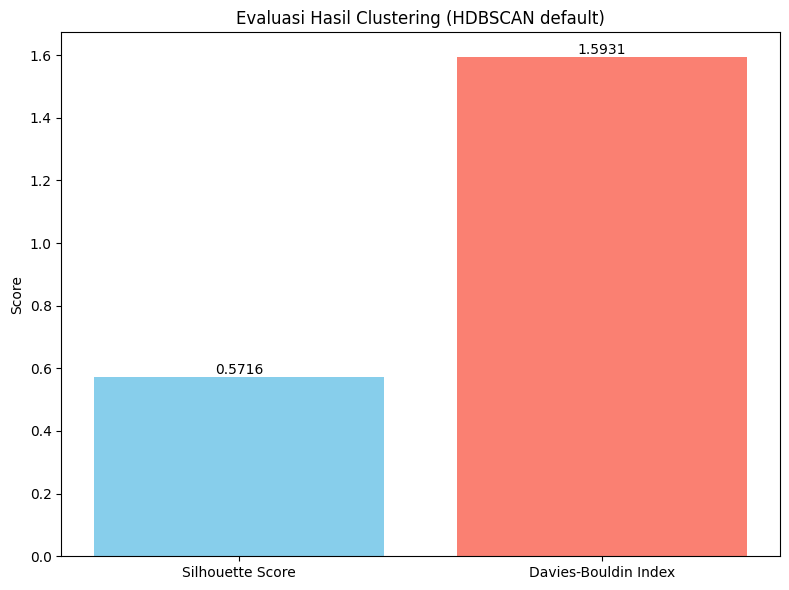

In [11]:
# ---------------------------------------------------------------- Langkah 10-12
print("[Langkah 10-11] Evaluasi clustering HDBSCAN default")
sil_score = silhouette_score(X, hdb.labels_)
dbi_score = davies_bouldin_score(X, hdb.labels_)
print(f"  Silhouette Score      : {sil_score:.4f}")
print(f"  Davies-Bouldin Index  : {dbi_score:.4f}")

scores = {"Silhouette Score": sil_score, "Davies-Bouldin Index": dbi_score}
fig, ax = plt.subplots(figsize=(8, 6))
bars = ax.bar(scores.keys(), scores.values(), color=["skyblue", "salmon"])
ax.bar_label(bars, fmt="%.4f")
ax.set_title("Evaluasi Hasil Clustering (HDBSCAN default)")
ax.set_ylabel("Score")
save(fig, "p2_evaluasi_bar.png")

df = pd.DataFrame(ROWS)
df.to_csv(OUT / "p2_metrik.csv", index=False)
print(f"\n[ringkasan] {len(df)} eksperimen, metrik -> output/p2_metrik.csv")
print(df.to_string(index=False))
print("\nCatatan: silhouette & DBI hanya dihitung bila cluster 2..n-1 dan noise "
      "diperlakukan sebagai anggota cluster; ARI dibanding label asli.")